# HexaMind — Stage 5 RUL Model Training & Evaluation (`FD001`)

Trains and benchmarks **XGBoost**, **LSTM**, **GRU**, and **1D-CNN** Remaining Useful Life (RUL) models with uncertainty estimation on NASA C-MAPSS `FD001`:
- **Aligned validation evaluation**: All models are evaluated on identical 30-cycle windows (`cycle >= 30`, 3,490 validation rows) to prevent horizon mismatch.
- **90% Prediction Intervals (`pi90`)**: XGBoost uses `0.05` and `0.95` quantile regressors; PyTorch sequence models (`LSTM`, `GRU`, `1D-CNN`) use `MSELoss` and 30-sample Monte Carlo Dropout.
- **Model Selection**: Strictly by validation RMSE (no test-set leakage).

In [1]:
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_DIR = PROJECT_ROOT / "src"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from features import WINDOW, create_windows, model_feature_columns
from models.rul import DLTrainConfig, SequenceRULTrainer, XGBoostRULModel
from train import _build_splits, _last_cycle_indices, _metrics, _train_dl_model, _train_xgboost

print("Project root:", PROJECT_ROOT)
print("Window size:", WINDOW)

Project root: C:\Users\Mega Store\Downloads\Depi Project Task 2 Completed
Window size: 30


In [2]:
splits = _build_splits()
feature_cols = model_feature_columns(splits["train"]["processed"].columns.tolist())
input_dim = len(feature_cols)

for split_name, data in splits.items():
    print(f"{split_name:>10}: X={data['X'].shape}, y={data['y'].shape}, engines={data['meta']['unit_id'].nunique()}")
print("Model input features:", input_dim)

     train: X=(14241, 30, 62), y=(14241,), engines=80
validation: X=(3490, 30, 62), y=(3490,), engines=20
      test: X=(10196, 30, 62), y=(10196,), engines=100
Model input features: 62


In [3]:
SEED = 42
EPOCHS = 35
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

runs = []
print("=== Training XGBOOST ===")
runs.append(_train_xgboost(splits, seed=SEED))

for arch in ("lstm", "gru", "cnn1d"):
    print(f"=== Training {arch.upper()} ===")
    runs.append(_train_dl_model(arch, splits, input_dim=input_dim, epochs=EPOCHS, seed=SEED))

best_run = min(runs, key=lambda r: r["validation"]["rmse"])
print(f"\nSelected best model by validation RMSE: {best_run['model'].upper()} ({best_run['validation']['rmse']})")

=== Training XGBOOST ===


=== Training LSTM ===


=== Training GRU ===


=== Training CNN1D ===



Selected best model by validation RMSE: GRU (10.9215)


In [4]:
rows = []
for r in runs:
    rows.append({
        "Model": r["model"].upper(),
        "Val RMSE": r["validation"]["rmse"],
        "Val MAE": r["validation"]["mae"],
        "Val PI90 Cov": r["validation"]["pi90_coverage"],
        "Test All RMSE": r["test_all_cycles"]["rmse"],
        "Test Last RMSE": r["test_last_cycle"]["rmse"],
        "Test Last MAE": r["test_last_cycle"]["mae"],
        "Test Last PI90 Cov": r["test_last_cycle"]["pi90_coverage"],
        "Artifact": r["artifact"],
    })

comparison_df = pd.DataFrame(rows).sort_values("Val RMSE").reset_index(drop=True)
comparison_df

,Model,Val RMSE,Val MAE,Val PI90 Cov,Test All RMSE,Test Last RMSE,Test Last MAE,Test Last PI90 Cov,Artifact
0,GRU,10.9215,8.5865,0.9166,14.0469,13.3973,9.3717,0.88,models/gru_rul.pt
1,LSTM,11.3090,9.0600,0.8983,13.6893,12.4818,9.1535,0.87,models/lstm_rul.pt
2,CNN1D,12.6869,10.1788,0.8476,14.9706,14.6224,10.4695,0.82,models/cnn1d_rul.pt
3,XGBOOST,15.7963,11.5704,0.8851,19.1240,16.8609,12.1062,0.90,models/xgboost_rul.joblib


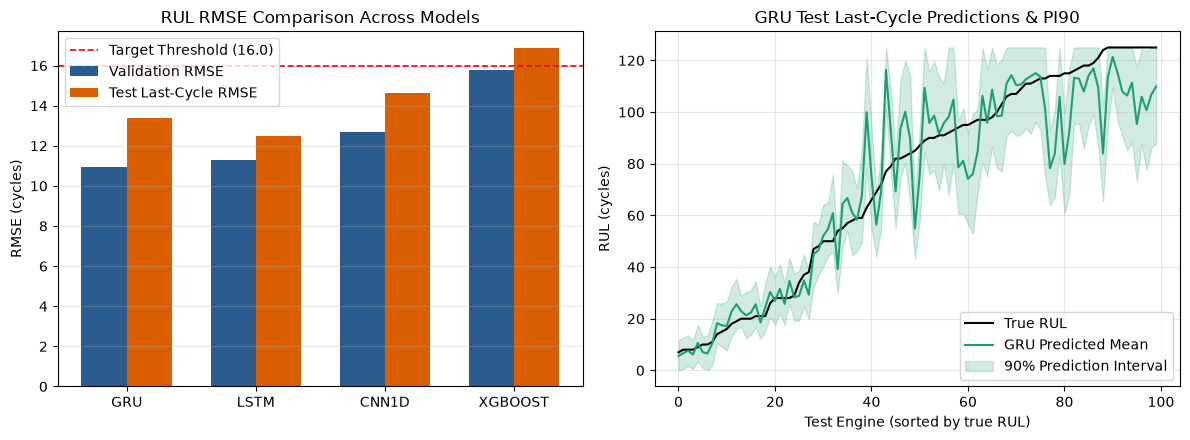

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

models = comparison_df["Model"]
x = np.arange(len(models))
width = 0.35

axes[0].bar(x - width / 2, comparison_df["Val RMSE"], width, label="Validation RMSE", color="#2b5c8f")
axes[0].bar(x + width / 2, comparison_df["Test Last RMSE"], width, label="Test Last-Cycle RMSE", color="#d95f02")
axes[0].axhline(16.0, color="red", linestyle="--", linewidth=1.2, label="Target Threshold (16.0)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(models)
axes[0].set_ylabel("RMSE (cycles)")
axes[0].set_title("RUL RMSE Comparison Across Models")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

best_model = SequenceRULTrainer.load(str(PROJECT_ROOT / best_run["artifact"]))
last_idx = _last_cycle_indices(splits["test"]["meta"])
X_test_last = splits["test"]["X"][last_idx]
y_test_last = splits["test"]["y"][last_idx]
unc = best_model.predict_with_uncertainty(X_test_last)

order = np.argsort(y_test_last)
axes[1].plot(y_test_last[order], label="True RUL", color="black", linewidth=1.5)
axes[1].plot(unc["rul_mean"][order], label=f"{best_run['model'].upper()} Predicted Mean", color="#1b9e77", linewidth=1.5)
axes[1].fill_between(
    np.arange(len(order)),
    unc["rul_lower"][order],
    unc["rul_upper"][order],
    color="#1b9e77",
    alpha=0.2,
    label="90% Prediction Interval",
)
axes[1].set_xlabel("Test Engine (sorted by true RUL)")
axes[1].set_ylabel("RUL (cycles)")
axes[1].set_title(f"{best_run['model'].upper()} Test Last-Cycle Predictions & PI90")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()